# Sentiment Analysis on Amazon Product Reviews

## OASIS INFOBYTE — Data Analytics Internship

**Task:** Sentiment Analysis
**Tools:** Python, Pandas, NumPy, Matplotlib, Seaborn, Scikit-learn
**Dataset:** Amazon Product Reviews

### Project Objective

The objective of this project is to analyse Amazon product reviews, clean messy text data, and classify customer sentiment using machine learning techniques.

### Project Workflow

- [ ] Import required libraries
- [ ] Load and inspect all CSV files
- [ ] Perform data quality analysis
- [ ] Clean missing values and duplicate records
- [ ] Preprocess review text
- [ ] Explore sentiment distribution
- [ ] Apply TF-IDF vectorization
- [ ] Train and compare machine learning models
- [ ] Evaluate model performance
- [ ] Document findings and conclusion


## 1. Import Required Libraries

In this step, we import the Python libraries required for data analysis, visualization, text processing, and machine learning.

- **Pandas:** Load and analyse CSV datasets.
- **NumPy:** Perform numerical operations.
- **Matplotlib:** Create charts and graphs.
- **Seaborn:** Create statistical visualizations.
- **Scikit-learn:** Build and evaluate machine learning models.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

print("All libraries imported successfully!")
print("Pandas version:", pd.__version__)
print("Scikit-learn version:", sklearn.__version__)

All libraries imported successfully!
Pandas version: 2.2.3
Scikit-learn version: 1.6.1


In [2]:
import pandas as pd

files = [
    "1429_1.csv",
    "Datafiniti_Amazon_Consumer_Reviews_of_Amazon_Products.csv",
    "Datafiniti_Amazon_Consumer_Reviews_of_Amazon_Products_May19.csv"
]

for file in files:
    data = pd.read_csv(file)
    print("\nFile:", file)
    print("Shape:", data.shape)
    print("Columns:", data.columns.tolist())
    print("Missing values:", data.isnull().sum().sum())
    print("Duplicate rows:", data.duplicated().sum())

C:\Users\Shivank Tiwari\AppData\Local\Temp\ipykernel_33268\1658661486.py:10: DtypeWarning: Columns (1,10) have mixed types. Specify dtype option on import or set low_memory=False.
  data = pd.read_csv(file)



File: 1429_1.csv
Shape: (34660, 21)
Columns: ['id', 'name', 'asins', 'brand', 'categories', 'keys', 'manufacturer', 'reviews.date', 'reviews.dateAdded', 'reviews.dateSeen', 'reviews.didPurchase', 'reviews.doRecommend', 'reviews.id', 'reviews.numHelpful', 'reviews.rating', 'reviews.sourceURLs', 'reviews.text', 'reviews.title', 'reviews.userCity', 'reviews.userProvince', 'reviews.username']
Missing values: 157230
Duplicate rows: 0

File: Datafiniti_Amazon_Consumer_Reviews_of_Amazon_Products.csv
Shape: (5000, 24)
Columns: ['id', 'dateAdded', 'dateUpdated', 'name', 'asins', 'brand', 'categories', 'primaryCategories', 'imageURLs', 'keys', 'manufacturer', 'manufacturerNumber', 'reviews.date', 'reviews.dateAdded', 'reviews.dateSeen', 'reviews.doRecommend', 'reviews.id', 'reviews.numHelpful', 'reviews.rating', 'reviews.sourceURLs', 'reviews.text', 'reviews.title', 'reviews.username', 'sourceURLs']
Missing values: 8933
Duplicate rows: 95

File: Datafiniti_Amazon_Consumer_Reviews_of_Amazon_Prod

## 3. Select and Inspect the Dataset

The Datafiniti Amazon Consumer Reviews dataset was selected for further analysis because it contains 5,000 records, 24 columns, missing values, and duplicate rows.

The dataset will be inspected to identify the review text and rating columns before performing data cleaning and sentiment classification.

In [3]:

file_path = "Datafiniti_Amazon_Consumer_Reviews_of_Amazon_Products.csv"

df = pd.read_csv(file_path)

print("Dataset Shape:", df.shape)
print("\nColumn Names:")
print(df.columns.tolist())

display(df.head(5))


Dataset Shape: (5000, 24)

Column Names:
['id', 'dateAdded', 'dateUpdated', 'name', 'asins', 'brand', 'categories', 'primaryCategories', 'imageURLs', 'keys', 'manufacturer', 'manufacturerNumber', 'reviews.date', 'reviews.dateAdded', 'reviews.dateSeen', 'reviews.doRecommend', 'reviews.id', 'reviews.numHelpful', 'reviews.rating', 'reviews.sourceURLs', 'reviews.text', 'reviews.title', 'reviews.username', 'sourceURLs']


,id,dateAdded,dateUpdated,name,asins,brand,categories,primaryCategories,imageURLs,keys,...,reviews.dateSeen,reviews.doRecommend,reviews.id,reviews.numHelpful,reviews.rating,reviews.sourceURLs,reviews.text,reviews.title,reviews.username,sourceURLs
0,AVqVGZNvQMlgsOJE6eUY,2017-03-03T16:56:05Z,2018-10-25T16:36:31Z,"Amazon Kindle E-Reader 6"" Wifi (8th Generation...",B00ZV9PXP2,Amazon,"Computers,Electronics Features,Tablets,Electro...",Electronics,https://pisces.bbystatic.com/image2/BestBuy_US...,allnewkindleereaderblack6glarefreetouchscreend...,...,"2018-05-27T00:00:00Z,2017-09-18T00:00:00Z,2017...",False,NaN,0,3,http://reviews.bestbuy.com/3545/5442403/review...,I thought it would be as big as small paper bu...,Too small,llyyue,https://www.newegg.com/Product/Product.aspx%25...
1,AVqVGZNvQMlgsOJE6eUY,2017-03-03T16:56:05Z,2018-10-25T16:36:31Z,"Amazon Kindle E-Reader 6"" Wifi (8th Generation...",B00ZV9PXP2,Amazon,"Computers,Electronics Features,Tablets,Electro...",Electronics,https://pisces.bbystatic.com/image2/BestBuy_US...,allnewkindleereaderblack6glarefreetouchscreend...,...,"2018-05-27T00:00:00Z,2017-07-07T00:00:00Z,2017...",True,NaN,0,5,http://reviews.bestbuy.com/3545/5442403/review...,This kindle is light and easy to use especiall...,Great light reader. Easy to use at the beach,Charmi,https://www.newegg.com/Product/Product.aspx%25...
2,AVqVGZNvQMlgsOJE6eUY,2017-03-03T16:56:05Z,2018-10-25T16:36:31Z,"Amazon Kindle E-Reader 6"" Wifi (8th Generation...",B00ZV9PXP2,Amazon,"Computers,Electronics Features,Tablets,Electro...",Electronics,https://pisces.bbystatic.com/image2/BestBuy_US...,allnewkindleereaderblack6glarefreetouchscreend...,...,2018-05-27T00:00:00Z,True,NaN,0,4,https://reviews.bestbuy.com/3545/5442403/revie...,Didnt know how much i'd use a kindle so went f...,Great for the price,johnnyjojojo,https://www.newegg.com/Product/Product.aspx%25...
3,AVqVGZNvQMlgsOJE6eUY,2017-03-03T16:56:05Z,2018-10-25T16:36:31Z,"Amazon Kindle E-Reader 6"" Wifi (8th Generation...",B00ZV9PXP2,Amazon,"Computers,Electronics Features,Tablets,Electro...",Electronics,https://pisces.bbystatic.com/image2/BestBuy_US...,allnewkindleereaderblack6glarefreetouchscreend...,...,2018-10-09T00:00:00Z,True,177283626.0,3,5,https://redsky.target.com/groot-domain-api/v1/...,I am 100 happy with my purchase. I caught it o...,A Great Buy,Kdperry,https://www.newegg.com/Product/Product.aspx%25...
4,AVqVGZNvQMlgsOJE6eUY,2017-03-03T16:56:05Z,2018-10-25T16:36:31Z,"Amazon Kindle E-Reader 6"" Wifi (8th Generation...",B00ZV9PXP2,Amazon,"Computers,Electronics Features,Tablets,Electro...",Electronics,https://pisces.bbystatic.com/image2/BestBuy_US...,allnewkindleereaderblack6glarefreetouchscreend...,...,2018-05-27T00:00:00Z,True,NaN,0,5,https://reviews.bestbuy.com/3545/5442403/revie...,Solid entry level Kindle. Great for kids. Gift...,Solid entry-level Kindle. Great for kids,Johnnyblack,https://www.newegg.com/Product/Product.aspx%25...


### Initial Observations

The selected dataset has been loaded successfully. The next step is to identify the review text and rating columns, inspect their data types, and investigate missing or inconsistent values.

No data cleaning has been performed yet.

## 4. Inspect Column Names and Data Quality

In this step, we examine all column names, data types, missing values, and duplicate records. We also identify the columns containing customer reviews and ratings for sentiment analysis.

No records will be removed at this stage.

In [4]:

# Display all columns clearly
for column in df.columns:
    print(column)

print("\nDataset Information:")
df.info()

print("\nMissing Values by Column:")
display(df.isnull().sum().sort_values(ascending=False).to_frame("Missing Values"))

print("\nExact Duplicate Rows:", df.duplicated().sum())


id
dateAdded
dateUpdated
name
asins
brand
categories
primaryCategories
imageURLs
keys
manufacturer
manufacturerNumber
reviews.date
reviews.dateAdded
reviews.dateSeen
reviews.doRecommend
reviews.id
reviews.numHelpful
reviews.rating
reviews.sourceURLs
reviews.text
reviews.title
reviews.username
sourceURLs

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 24 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   id                   5000 non-null   object 
 1   dateAdded            5000 non-null   object 
 2   dateUpdated          5000 non-null   object 
 3   name                 5000 non-null   object 
 4   asins                5000 non-null   object 
 5   brand                5000 non-null   object 
 6   categories           5000 non-null   object 
 7   primaryCategories    5000 non-null   object 
 8   imageURLs            5000 non-null   object 
 9   keys       

,Missing Values
reviews.id,4971
reviews.dateAdded,3948
reviews.title,13
reviews.username,1
id,0
dateAdded,0
dateUpdated,0
name,0
primaryCategories,0
categories,0



Exact Duplicate Rows: 95


## 5. Data Quality Report

The selected dataset contains 5,000 rows and 24 columns.

### Findings

- **Duplicate records:** 95 exact duplicate rows were identified.
- **Missing review IDs:** 4,971 values are missing in `reviews.id`.
- **Missing review dates added:** 3,948 values are missing in `reviews.dateAdded`.
- **Missing review titles:** 13 values are missing in `reviews.title`.
- **Missing usernames:** 1 value is missing in `reviews.username`.
- **Review text and ratings:** No missing values were found in `reviews.text` and `reviews.rating`.

### Initial Assessment

The review text and rating columns are complete, making them suitable candidates for sentiment analysis. Missing review IDs and date-added values will be investigated, while duplicate records will be verified before removal.

In [5]:

print("Review Text Data Type:", df["reviews.text"].dtype)
print("Rating Data Type:", df["reviews.rating"].dtype)

print("\nRating Distribution:")
display(df["reviews.rating"].value_counts().sort_index())

print("\nSample Reviews:")
display(df[["reviews.rating", "reviews.text"]].head(10))

print("\nMissing Review Text:", df["reviews.text"].isnull().sum())
print("Missing Ratings:", df["reviews.rating"].isnull().sum())


Review Text Data Type: object
Rating Data Type: int64

Rating Distribution:


reviews.rating
1      63
2      54
3     197
4    1208
5    3478
Name: count, dtype: int64


Sample Reviews:


,reviews.rating,reviews.text
0,3,I thought it would be as big as small paper bu...
1,5,This kindle is light and easy to use especiall...
2,4,Didnt know how much i'd use a kindle so went f...
3,5,I am 100 happy with my purchase. I caught it o...
4,5,Solid entry level Kindle. Great for kids. Gift...
5,5,This make an excellent ebook reader. Don't exp...
6,5,"I ordered this for my daughter, as I have the ..."
7,4,I bought my Kindle about 2 months ago and the ...
8,5,"amazon kindle is always the best ebook, upgrad..."
9,5,"It's beyond my expectation, and it can even sh..."



Missing Review Text: 0
Missing Ratings: 0


## 6. Rating Distribution and Sentiment Labels

The rating distribution shows that 5-star reviews are the most frequent, followed by 4-star reviews. Ratings of 1 and 2 stars are comparatively rare.

For this project, ratings will be mapped as follows:

- **Negative:** Ratings 1 and 2
- **Neutral:** Rating 3
- **Positive:** Ratings 4 and 5

This mapping converts numerical product ratings into three sentiment classes. Since the classes are imbalanced, model performance will be evaluated using precision, recall, and F1-score in addition to accuracy.

In [6]:

# Create sentiment labels from product ratings
def assign_sentiment(rating):
    if rating <= 2:
        return "Negative"
    elif rating == 3:
        return "Neutral"
    else:
        return "Positive"

df["sentiment"] = df["reviews.rating"].apply(assign_sentiment)

print("Sentiment labels created successfully!")
display(df[["reviews.rating", "reviews.text", "sentiment"]].head(10))

print("\nSentiment Counts:")
display(df["sentiment"].value_counts())


Sentiment labels created successfully!


,reviews.rating,reviews.text,sentiment
0,3,I thought it would be as big as small paper bu...,Neutral
1,5,This kindle is light and easy to use especiall...,Positive
2,4,Didnt know how much i'd use a kindle so went f...,Positive
3,5,I am 100 happy with my purchase. I caught it o...,Positive
4,5,Solid entry level Kindle. Great for kids. Gift...,Positive
5,5,This make an excellent ebook reader. Don't exp...,Positive
6,5,"I ordered this for my daughter, as I have the ...",Positive
7,4,I bought my Kindle about 2 months ago and the ...,Positive
8,5,"amazon kindle is always the best ebook, upgrad...",Positive
9,5,"It's beyond my expectation, and it can even sh...",Positive



Sentiment Counts:


sentiment
Positive    4686
Neutral      197
Negative     117
Name: count, dtype: int64

### Observation

Sentiment labels were created from the product ratings. The original rating column was preserved, and the new sentiment column contains Negative, Neutral, and Positive labels.

The class distribution will be examined before model training to understand the imbalance between sentiment categories.

## 7. Duplicate Removal

During the initial data quality assessment, 95 exact duplicate rows were identified.

Exact duplicate records can affect analysis by counting the same record more than once. These rows will be removed, and the number of records before and after removal will be documented.

The original loaded dataset will remain unchanged in a separate variable for comparison.

In [7]:

# Preserve the dataset before removing duplicates
df_before_deduplication = df.copy()

rows_before = len(df)

# Remove exact duplicate rows
df = df.drop_duplicates().copy()

rows_after = len(df)
duplicates_removed = rows_before - rows_after

print("Rows before duplicate removal:", rows_before)
print("Rows after duplicate removal:", rows_after)
print("Duplicate rows removed:", duplicates_removed)
print("Remaining exact duplicates:", df.duplicated().sum())


Rows before duplicate removal: 5000
Rows after duplicate removal: 4905
Duplicate rows removed: 95
Remaining exact duplicates: 0


### Observation

Exact duplicate rows were removed using Pandas `drop_duplicates()`.

The dataset contained 5,000 rows before removal. The number of remaining rows and the exact number of removed duplicates were verified after cleaning.

This step helps prevent exact duplicate records from being counted multiple times during analysis.

## 8. Review Text Cleaning and Standardisation

Customer reviews may contain inconsistent capitalization and unnecessary whitespace. In this step, we will standardise the review text by converting it to lowercase and removing leading, trailing, and repeated whitespace.

The original review text will be preserved in a separate column for comparison. We will avoid removing punctuation at this stage because punctuation can carry useful sentiment information.

In [8]:

# Preserve the original review text
df["reviews.text_original"] = df["reviews.text"]

# Standardise review text
df["reviews.text"] = (
    df["reviews.text"]
    .astype(str)
    .str.lower()
    .str.replace(r"\s+", " ", regex=True)
    .str.strip()
)

print("Text standardisation completed!")

display(
    df[["reviews.text_original", "reviews.text"]].head(10)
)


Text standardisation completed!


,reviews.text_original,reviews.text
0,I thought it would be as big as small paper bu...,i thought it would be as big as small paper bu...
1,This kindle is light and easy to use especiall...,this kindle is light and easy to use especiall...
2,Didnt know how much i'd use a kindle so went f...,didnt know how much i'd use a kindle so went f...
3,I am 100 happy with my purchase. I caught it o...,i am 100 happy with my purchase. i caught it o...
4,Solid entry level Kindle. Great for kids. Gift...,solid entry level kindle. great for kids. gift...
5,This make an excellent ebook reader. Don't exp...,this make an excellent ebook reader. don't exp...
6,"I ordered this for my daughter, as I have the ...","i ordered this for my daughter, as i have the ..."
7,I bought my Kindle about 2 months ago and the ...,i bought my kindle about 2 months ago and the ...
8,"amazon kindle is always the best ebook, upgrad...","amazon kindle is always the best ebook, upgrad..."
9,"It's beyond my expectation, and it can even sh...","it's beyond my expectation, and it can even sh..."


### Observation

The review text was standardised by converting it to lowercase and removing unnecessary whitespace. The original text was preserved to support before-and-after comparison.

Punctuation and the wording of reviews were retained to avoid unnecessary loss of sentiment-related information.

## 9. Missing Value Handling and Data Type Validation

The initial data quality report identified missing values in several metadata columns. The review text and rating columns contained no missing values.

Since review text and ratings are required for sentiment classification, records missing either field will be excluded if any are found after cleaning. Missing metadata fields will be retained unless they are required for the analysis. Date columns will also be checked before conversion.

In [9]:

# Check missing values in important columns
important_columns = ["reviews.text", "reviews.rating", "sentiment"]

print("Missing values before handling:")
display(df[important_columns].isnull().sum())

rows_before = len(df)

# Remove records only if required sentiment fields are missing
df = df.dropna(subset=important_columns).copy()

print("\nRows before handling:", rows_before)
print("Rows after handling:", len(df))
print("Rows removed:", rows_before - len(df))

# Convert review date columns to datetime
for column in ["reviews.date", "dateAdded", "dateUpdated"]:
    if column in df.columns:
        df[column] = pd.to_datetime(df[column], errors="coerce", utc=True)

print("\nUpdated date column types:")
display(df[["reviews.date", "dateAdded", "dateUpdated"]].dtypes)


Missing values before handling:


reviews.text      0
reviews.rating    0
sentiment         0
dtype: int64


Rows before handling: 4905
Rows after handling: 4905
Rows removed: 0

Updated date column types:


reviews.date    datetime64[ns, UTC]
dateAdded       datetime64[ns, UTC]
dateUpdated     datetime64[ns, UTC]
dtype: object

### Observation

Missing values were checked in the review text, rating, and sentiment columns. Records missing required sentiment fields were excluded, if any were present.

Review date columns were converted to datetime format. Invalid or missing dates were retained as missing datetime values rather than deleting otherwise usable reviews.

## 10. Sentiment Distribution Analysis

In this step, we analyse the distribution of positive, negative, and neutral reviews using a bar chart.

This visualization helps identify class imbalance before training machine learning models. The findings will guide the choice of evaluation metrics.

Sentiment Distribution:


,Number of Reviews
sentiment,
Positive,4600
Neutral,193
Negative,112


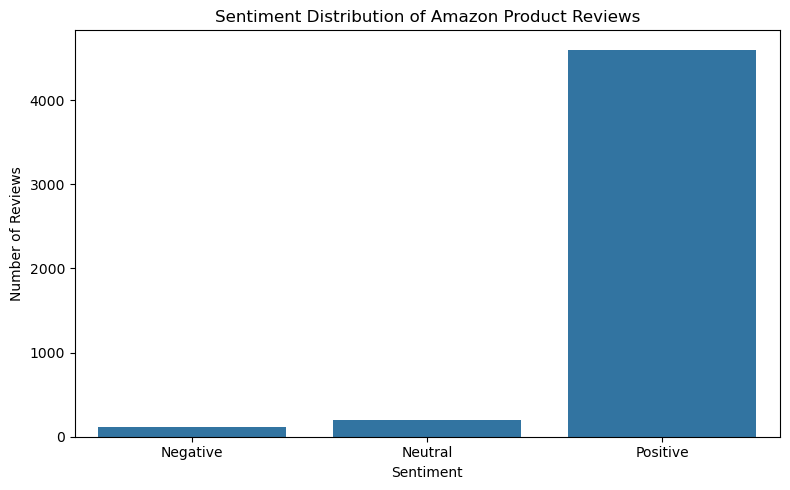

In [10]:

# Count reviews in each sentiment category
sentiment_counts = df["sentiment"].value_counts()

print("Sentiment Distribution:")
display(sentiment_counts.to_frame("Number of Reviews"))

# Plot sentiment distribution
plt.figure(figsize=(8, 5))
sns.countplot(
    data=df,
    x="sentiment",
    order=["Negative", "Neutral", "Positive"]
)

plt.title("Sentiment Distribution of Amazon Product Reviews")
plt.xlabel("Sentiment")
plt.ylabel("Number of Reviews")
plt.tight_layout()
plt.show()


### Observation

The bar chart shows the distribution of negative, neutral, and positive customer reviews. The counts indicate whether the dataset is balanced or dominated by a particular sentiment category.

**Finding:** To be completed after reviewing the chart.

**Implication:** If the sentiment classes are imbalanced, model evaluation will include precision, recall, and F1-score rather than relying only on accuracy.

## 11. Text Preprocessing

Text preprocessing converts customer reviews into a consistent format suitable for machine learning.

In this step, we will tokenize review text and remove common English stop words. The cleaned text will be stored in a separate column so that the original review remains available for comparison.## 11. Text Preprocessing

Text preprocessing converts customer reviews into a consistent format suitable for machine learning.

In this step, we will tokenize review text and remove common English stop words. The cleaned text will be stored in a separate column so that the original review remains available for comparison.

In [11]:
import re
import nltk

from nltk.corpus import stopwords
from nltk.tokenize import wordpunct_tokenize

nltk.download("stopwords")

stop_words = set(stopwords.words("english"))

def preprocess_text(text):
    text = str(text).lower()
    tokens = wordpunct_tokenize(text)

    # Keep words and preserve negation terms
    tokens = [
        word for word in tokens
        if re.search(r"[a-z]", word)
        and word not in {"not", "no", "nor"}
        and word not in stop_words
    ]

    return " ".join(tokens)

df["cleaned_text"] = df["reviews.text"].apply(preprocess_text)

display(df[["reviews.text", "cleaned_text", "sentiment"]].head(10))

[nltk_data] Downloading package stopwords to C:\Users\Shivank
[nltk_data]     Tiwari\AppData\Roaming\nltk_data...
[nltk_data]   Unzipping corpora\stopwords.zip.


,reviews.text,cleaned_text,sentiment
0,i thought it would be as big as small paper bu...,thought would big small paper turn like palm t...,Neutral
1,this kindle is light and easy to use especiall...,kindle light easy use especially beach,Positive
2,didnt know how much i'd use a kindle so went f...,didnt know much use kindle went lower end im h...,Positive
3,i am 100 happy with my purchase. i caught it o...,happy purchase caught sale really good price n...,Positive
4,solid entry level kindle. great for kids. gift...,solid entry level kindle great kids gifted kid...,Positive
5,this make an excellent ebook reader. don't exp...,make excellent ebook reader expect much device...,Positive
6,"i ordered this for my daughter, as i have the ...",ordered daughter black paperwhite love read qu...,Positive
7,i bought my kindle about 2 months ago and the ...,bought kindle months ago battery already dead ...,Positive
8,"amazon kindle is always the best ebook, upgrad...",amazon kindle always best ebook upgrade every ...,Positive
9,"it's beyond my expectation, and it can even sh...",beyond expectation even show music score fast ...,Positive


## 12. TF-IDF Feature Extraction

TF-IDF (Term Frequency-Inverse Document Frequency) converts text reviews into numerical features.

It gives importance to words based on their frequency in a review and how common they are across all reviews.

We will use TF-IDF with unigrams and bigrams to capture individual words and two-word phrases.

In [12]:
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer

# Select cleaned reviews and sentiment labels
X = df["cleaned_text"]
y = df["sentiment"]

# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Convert text into TF-IDF numerical features
tfidf = TfidfVectorizer(
    max_features=10000,
    ngram_range=(1, 2),
    min_df=2
)

X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

print("Training samples:", X_train_tfidf.shape[0])
print("Testing samples:", X_test_tfidf.shape[0])
print("Number of TF-IDF features:", X_train_tfidf.shape[1])
print("TF-IDF conversion completed successfully!")

Training samples: 3924
Testing samples: 981
Number of TF-IDF features: 10000
TF-IDF conversion completed successfully!



## 13. Train the Multinomial Naive Bayes Model

Multinomial Naive Bayes is a machine learning algorithm commonly used for text classification.

In this project, it will learn patterns from TF-IDF features and predict whether an Amazon product review is Positive, Neutral, or Negative.


In [13]:

from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score, classification_report

# Initialize the model
nb_model = MultinomialNB()

# Train the model using training data
nb_model.fit(X_train_tfidf, y_train)

# Predict sentiment for test reviews
y_pred_nb = nb_model.predict(X_test_tfidf)

# Evaluate model accuracy
nb_accuracy = accuracy_score(y_test, y_pred_nb)

print("Multinomial Naive Bayes Model Results")
print("-------------------------------------")
print(f"Accuracy: {nb_accuracy:.4f}")
print(f"Accuracy Percentage: {nb_accuracy * 100:.2f}%")

print("\nClassification Report:")
print(classification_report(y_test, y_pred_nb, zero_division=0))


Multinomial Naive Bayes Model Results
-------------------------------------
Accuracy: 0.9378
Accuracy Percentage: 93.78%

Classification Report:
              precision    recall  f1-score   support

    Negative       0.00      0.00      0.00        22
     Neutral       0.00      0.00      0.00        39
    Positive       0.94      1.00      0.97       920

    accuracy                           0.94       981
   macro avg       0.31      0.33      0.32       981
weighted avg       0.88      0.94      0.91       981




## 14. Train the Logistic Regression Model

Logistic Regression is a supervised machine learning algorithm used for classification.

In this project, it will learn from TF-IDF features and classify Amazon product reviews into Positive, Neutral, and Negative sentiments.

We will compare its performance with the Multinomial Naive Bayes model.


In [14]:

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report

# Initialize the Logistic Regression model
lr_model = LogisticRegression(
    max_iter=1000,
    class_weight="balanced",
    random_state=42
)

# Train the model
lr_model.fit(X_train_tfidf, y_train)

# Predict sentiment for test reviews
y_pred_lr = lr_model.predict(X_test_tfidf)

# Calculate model accuracy
lr_accuracy = accuracy_score(y_test, y_pred_lr)

print("Logistic Regression Model Results")
print("---------------------------------")
print(f"Accuracy: {lr_accuracy:.4f}")
print(f"Accuracy Percentage: {lr_accuracy * 100:.2f}%")

print("\nClassification Report:")
print(classification_report(y_test, y_pred_lr, zero_division=0))


Logistic Regression Model Results
---------------------------------
Accuracy: 0.9174
Accuracy Percentage: 91.74%

Classification Report:
              precision    recall  f1-score   support

    Negative       0.50      0.36      0.42        22
     Neutral       0.24      0.28      0.26        39
    Positive       0.96      0.96      0.96       920

    accuracy                           0.92       981
   macro avg       0.57      0.53      0.55       981
weighted avg       0.92      0.92      0.92       981




## 15. Model Comparison

In this step, we compare Multinomial Naive Bayes and Logistic Regression using their accuracy, precision, recall, and F1-score.

The comparison will help us identify which model performs better on the Amazon product review dataset.


In [15]:

from sklearn.metrics import accuracy_score, precision_recall_fscore_support

# Calculate weighted evaluation metrics
nb_precision, nb_recall, nb_f1, _ = precision_recall_fscore_support(
    y_test, y_pred_nb, average="weighted", zero_division=0
)

lr_precision, lr_recall, lr_f1, _ = precision_recall_fscore_support(
    y_test, y_pred_lr, average="weighted", zero_division=0
)

# Create a comparison table
model_comparison = pd.DataFrame({
    "Model": ["Multinomial Naive Bayes", "Logistic Regression"],
    "Accuracy": [
        accuracy_score(y_test, y_pred_nb),
        accuracy_score(y_test, y_pred_lr)
    ],
    "Weighted Precision": [nb_precision, lr_precision],
    "Weighted Recall": [nb_recall, lr_recall],
    "Weighted F1-Score": [nb_f1, lr_f1]
})

display(
    model_comparison.style.format({
        "Accuracy": "{:.2%}",
        "Weighted Precision": "{:.3f}",
        "Weighted Recall": "{:.3f}",
        "Weighted F1-Score": "{:.3f}"
    })
)


,Model,Accuracy,Weighted Precision,Weighted Recall,Weighted F1-Score
0,Multinomial Naive Bayes,93.78%,0.880,0.938,0.908
1,Logistic Regression,91.74%,0.920,0.917,0.918


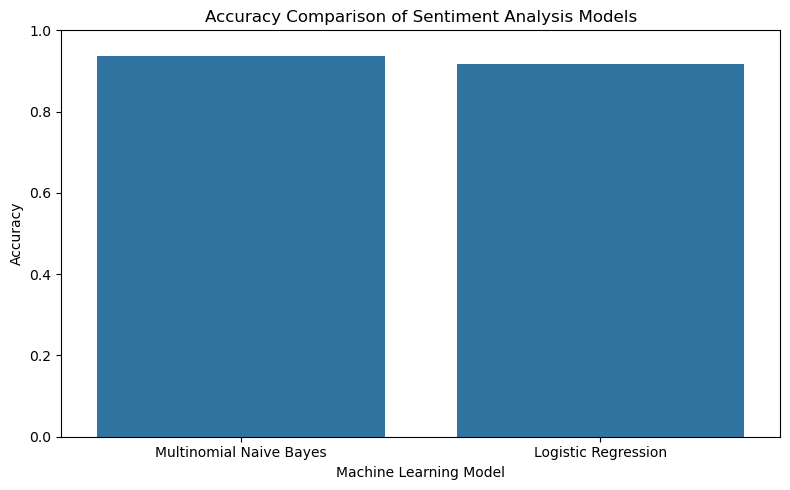

In [16]:

plt.figure(figsize=(8, 5))

sns.barplot(
    data=model_comparison,
    x="Model",
    y="Accuracy"
)

plt.title("Accuracy Comparison of Sentiment Analysis Models")
plt.xlabel("Machine Learning Model")
plt.ylabel("Accuracy")
plt.ylim(0, 1)
plt.tight_layout()
plt.show()



## 16. Confusion Matrix Evaluation

A confusion matrix compares actual sentiment labels with predicted sentiment labels.

It helps identify which sentiment classes are correctly classified and which classes are confused with one another.

We will evaluate both Multinomial Naive Bayes and Logistic Regression models.


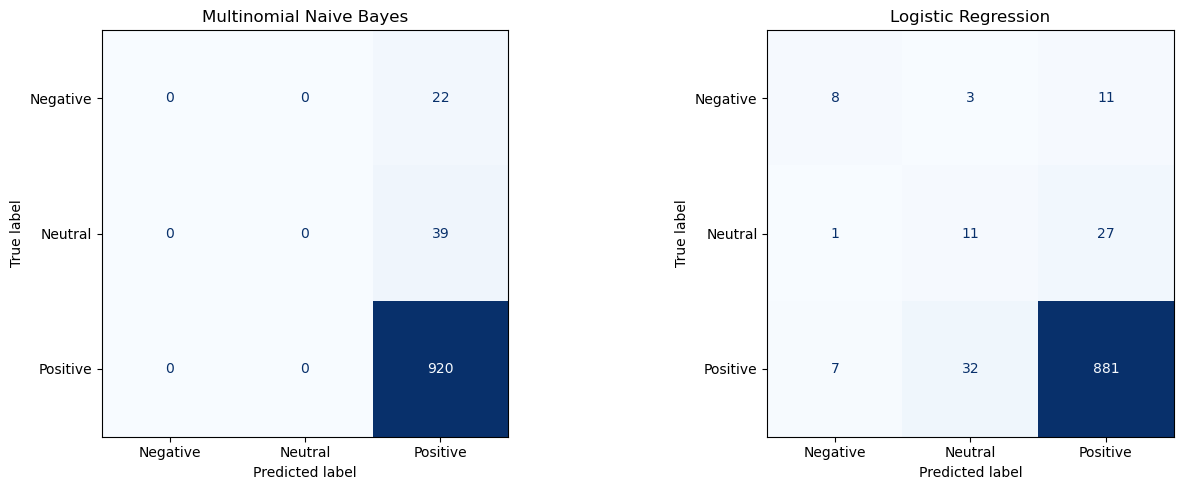

In [17]:

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Define sentiment label order
labels = ["Negative", "Neutral", "Positive"]

# Create confusion matrices for both models
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, predictions, model_name in zip(
    axes,
    [y_pred_nb, y_pred_lr],
    ["Multinomial Naive Bayes", "Logistic Regression"]
):
    cm = confusion_matrix(
        y_test,
        predictions,
        labels=labels
    )

    display_matrix = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=labels
    )

    display_matrix.plot(
        ax=ax,
        cmap="Blues",
        values_format="d",
        colorbar=False
    )

    ax.set_title(model_name)

plt.tight_layout()
plt.show()


In [18]:

print("Logistic Regression: Class-wise Performance")

print(
    classification_report(
        y_test,
        y_pred_lr,
        labels=["Negative", "Neutral", "Positive"],
        zero_division=0
    )
)


Logistic Regression: Class-wise Performance
              precision    recall  f1-score   support

    Negative       0.50      0.36      0.42        22
     Neutral       0.24      0.28      0.26        39
    Positive       0.96      0.96      0.96       920

    accuracy                           0.92       981
   macro avg       0.57      0.53      0.55       981
weighted avg       0.92      0.92      0.92       981




## 17. Final Model Evaluation and Findings

In this section, we summarize the performance of both sentiment classification models and identify the better-performing model based on evaluation metrics.

The project uses Amazon product reviews to classify customer opinions into Positive, Neutral, and Negative sentiments.


In [19]:

# Identify the model with the highest weighted F1-score
best_index = model_comparison["Weighted F1-Score"].idxmax()
best_model_name = model_comparison.loc[best_index, "Model"]

print("FINAL MODEL COMPARISON")
print("=" * 40)
display(model_comparison)

print("\nModel with the highest weighted F1-score:", best_model_name)
print(
    "Weighted F1-score:",
    f"{model_comparison.loc[best_index, 'Weighted F1-Score']:.3f}"
)


FINAL MODEL COMPARISON


,Model,Accuracy,Weighted Precision,Weighted Recall,Weighted F1-Score
0,Multinomial Naive Bayes,0.937819,0.879504,0.937819,0.907725
1,Logistic Regression,0.917431,0.919760,0.917431,0.918284



Model with the highest weighted F1-score: Logistic Regression
Weighted F1-score: 0.918


In [20]:

from pathlib import Path

# Create the output folder if it does not exist
output_dir = Path("outputs")
output_dir.mkdir(parents=True, exist_ok=True)

# Save model comparison results
model_comparison.to_csv(
    output_dir / "model_comparison.csv",
    index=False
)

# Save the cleaned dataset with sentiment labels
df.to_csv(
    output_dir / "cleaned_sentiment_reviews.csv",
    index=False
)

print("Output files saved successfully!")
print("1. outputs/model_comparison.csv")
print("2. outputs/cleaned_sentiment_reviews.csv")


Output files saved successfully!
1. outputs/model_comparison.csv
2. outputs/cleaned_sentiment_reviews.csv



## 18. Conclusion

This project analyzes Amazon product reviews using Python and machine learning.

The dataset was inspected for missing values and duplicate records. Review text was standardized and preprocessed, and sentiment labels were created from product ratings.

TF-IDF was used to convert review text into numerical features. Multinomial Naive Bayes and Logistic Regression were trained and evaluated using accuracy, precision, recall, F1-score, and confusion matrices.

The models were compared to identify their strengths and limitations. Since the dataset contains many more Positive reviews than Negative and Neutral reviews, class-wise evaluation is important.

This project demonstrates how machine learning can help analyze customer feedback and understand product sentiment.
